# Figure 6 — Large-velocity-mismatch regime

* **(a)** Sideband probabilities for electrons injected far from phase matching, $a=10^4$, $g=0.1$. The field is
  phase-matched to the simulation sideband $\ell_{\rm sim}=0$; nine electrons are injected at
  $\ell_{\rm sim}=\ell_0\in\{0,\pm100,\pm150,\pm200,\pm250\}$. Because the populated sideband ranges of these electrons do
  not overlap and the equations are linear, the nine cases are computed in a single propagation of the summed initial
  state.
* **(b)** Close-up of the boxed region of (a).
* **(c)** The same close-up in the nonrecoil limit ($a=10^{12}$), with a phase mismatch chosen to reproduce
  the oscillation of (b).

**Orientation of the vertical axis.** As in the published figure (original plotting script: `imshow(...,
origin="upper", extent=[0, zeta_max, -l_max, l_max])`), the simulation index $\ell_{\rm sim}$ is displayed with its
sign reversed, i.e. the vertical coordinate of the plot is $y=-\ell_{\rm sim}$. The data files contain $\ell_{\rm sim}$.

**Data files** (plain-text CSV, see `data/README.md`): `data/fig6/fig6ab_P.csv` (panels a, b) and `data/fig6/fig6c_P.csv`
(sideband maps, rows $\ell_{\rm sim}$, columns $\zeta$), `data/fig6/fig6a_injected_sidebands.csv` and
`data/fig6/fig6_parameters.csv`.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.colors import LogNorm
import pinem_recoil as pr

DATA = Path("data") / "fig6"
FIGS = Path("figures")
DATA.mkdir(parents=True, exist_ok=True)
FIGS.mkdir(exist_ok=True)

RECOMPUTE = False

## Parameters

In [2]:
a = 10000
g = 0.1
l_max = 270
zeta_max = 600
d_zeta = 1
d_phi = -d_zeta                       # phase matched to l_sim = 0
offsets = np.array([-250, -200, -150, -100, 0, 100, 150, 200, 250])

# panel (c): nonrecoil limit
a_c = 1e12
l_max_c = 50
d_phi_c = d_phi * (1 + 2 * 95 / a)    # phase mismatch reproducing the oscillation of (b)

## Computation

In [3]:
file_ab = DATA / "fig6ab_P.csv"
file_c = DATA / "fig6c_P.csv"
file_inj = DATA / "fig6a_injected_sidebands.csv"
file_par = DATA / "fig6_parameters.csv"
if RECOMPUTE or not all(f.exists() for f in [file_ab, file_c, file_inj, file_par]):
    psi0 = sum(pr.initial_state(l_max, a, ell0) for ell0 in offsets)
    zeta, phi = pr.propagate_steps(a, g, l_max, d_zeta, d_phi, zeta_max, initial=psi0)
    zeta_c, phi_c = pr.propagate_steps(a_c, g, l_max_c, d_zeta, d_phi_c, zeta_max)
    ell = pr.sideband_axis(l_max)
    ell_c = pr.sideband_axis(l_max_c)
    pr.save_map(file_ab, np.abs(phi)**2, zeta, ell, "zeta", "ell_sim")
    pr.save_map(file_c, np.abs(phi_c)**2, zeta_c, ell_c, "zeta", "ell_sim")
    pr.save_columns(file_inj, ell0_sim=offsets)
    pr.save_parameters(file_par, [
        ("a", a, "recoil parameter of panels (a) and (b)"),
        ("g", g, "coupling strength"),
        ("l_max", l_max, "sideband truncation of panels (a) and (b)"),
        ("d_zeta", d_zeta, "propagation step"),
        ("d_phi", d_phi, "field-phase step per step of panels (a) and (b): phase matching at ell_sim = 0"),
        ("a_c", a_c, "recoil parameter of panel (c) (nonrecoil limit)"),
        ("l_max_c", l_max_c, "sideband truncation of panel (c)"),
        ("d_phi_c", d_phi_c, "field-phase step per step of panel (c)"),
        ("plotted_vertical_axis", "-ell_sim", "vertical coordinate of the published figure (labelled l - l_ph)"),
    ])
    print("saved", file_ab, file_c, file_inj, file_par)

saved data\fig6\fig6ab_P.csv data\fig6\fig6c_P.csv data\fig6\fig6a_injected_sidebands.csv data\fig6\fig6_parameters.csv


## Load data and plot

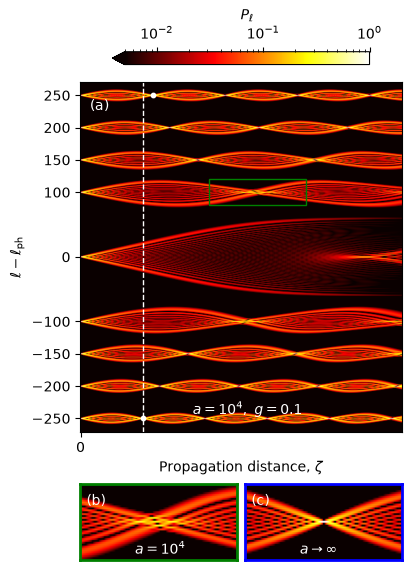

In [4]:
zeta, ell, P = pr.load_map(file_ab)
_, ell_c, P_c = pr.load_map(file_c)
offsets = pr.load_columns(file_inj)["ell0_sim"]
cmap = plt.get_cmap("hot").copy()
cmap.set_under(cmap(0.0)); cmap.set_bad(cmap(0.0))
norm = LogNorm(vmin=0.5e-2, vmax=1)

def show(ax, P, y):
    # rows ordered by ell_sim ascending, i.e. y descending -> origin="upper"
    return ax.imshow(P, aspect="auto", origin="upper", cmap=cmap, norm=norm,
                     extent=[zeta[0] - 0.5, zeta[-1] + 0.5, y[-1] - 0.5, y[0] + 0.5])

fig = plt.figure(figsize=(4, 5.6), constrained_layout=True)
gs = fig.add_gridspec(2, 2, height_ratios=[1.6, 0.35])
ax1 = fig.add_subplot(gs[0, :]); ax2 = fig.add_subplot(gs[1, 0]); ax3 = fig.add_subplot(gs[1, 1])

im = show(ax1, P, -ell)
ax1.set_xticks([0, zeta_max]); ax1.set_yticks(np.sort(-offsets))
ax1.set_xlabel(r"Propagation distance, $\zeta$")
ax1.set_ylabel(r"$\ell-\ell_{\rm ph}$")
ax1.text(0.03, 0.92, "(a)", color="w", transform=ax1.transAxes)
ax1.text(0.35, 0.05, r"$a=10^4,\ g=0.1$", color="w", transform=ax1.transAxes)
ax1.axvline(117, color="w", ls="--", lw=1)
ax1.scatter([117, 135], [-250, 250], s=10, c="w", zorder=3)
box = dict(z0=240, z1=420, l0=80, l1=120)
ax1.add_patch(patches.Rectangle((box["z0"], box["l0"]), box["z1"] - box["z0"], box["l1"] - box["l0"],
                                lw=1, edgecolor="green", facecolor="none"))

show(ax2, P, -ell)
ax2.set_xlim(box["z0"], box["z1"]); ax2.set_ylim(box["l0"], box["l1"])
show(ax3, P_c, -ell_c)
ax3.set_xlim(box["z0"], box["z1"]); ax3.set_ylim(-20, 20)
for ax, col, lab, txt in [(ax2, "green", "(b)", r"$a=10^4$"), (ax3, "blue", "(c)", r"$a\to\infty$")]:
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_edgecolor(col); sp.set_linewidth(2)
    ax.text(0.04, 0.72, lab, color="w", transform=ax.transAxes)
    ax.text(0.35, 0.08, txt, color="w", transform=ax.transAxes)
cb = fig.colorbar(im, ax=ax1, location="top", extend="min", shrink=0.8)
cb.set_label(r"$P_\ell$")
fig.savefig(FIGS / "fig6.png", dpi=200)
fig.savefig(FIGS / "fig6.pdf")
plt.show()